In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Define your dataset root path (adjust if your folder structure is different)
DATA_DIR = "../data"  # or "data/" depending on where your notebook is saved
classes = os.listdir(DATA_DIR)

print(f"Found dataset classes: {classes}")

Found dataset classes: ['processed', 'raw']


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_18824\1451553035.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), palette="viridis")


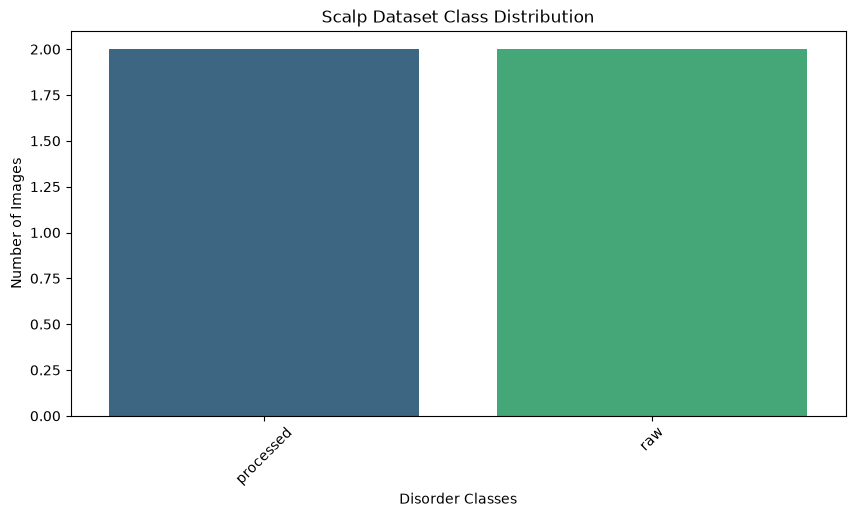

Image counts per class: {'processed': 2, 'raw': 2}


In [2]:
class_counts = {}
for cls in classes:
    cls_path = os.path.join(DATA_DIR, cls)
    if os.path.isdir(cls_path):
        class_counts[cls] = len(os.listdir(cls_path))

# Plot class distribution
plt.figure(figsize=(10, 5))
sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), palette="viridis")
plt.title("Scalp Dataset Class Distribution")
plt.xlabel("Disorder Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

print("Image counts per class:", class_counts)

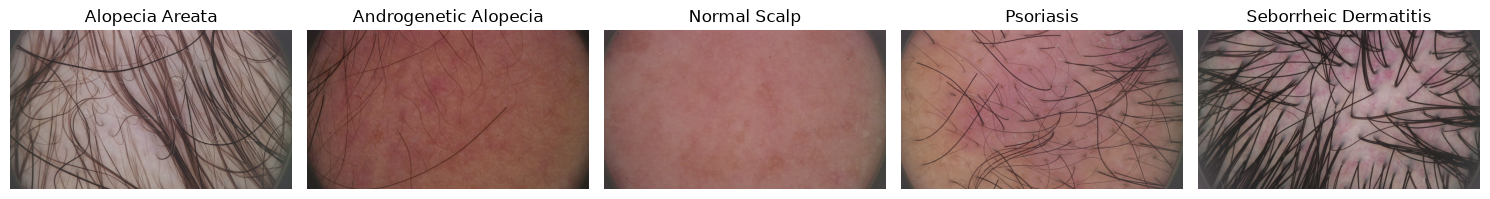

In [3]:
import os
from PIL import Image
import matplotlib.pyplot as plt

# Sahi absolute path set karein
DATA_DIR = r"D:\hairsclap\data\processed\train"

# Classes ki list lein
classes = os.listdir(DATA_DIR)

plt.figure(figsize=(15, 8))
for i, cls in enumerate(classes):
  cls_path = os.path.join(DATA_DIR, cls)
  
  if os.path.isdir(cls_path):
    images = os.listdir(cls_path)
    if len(images) > 0:
      sample_img_name = images[0]
      img_path = os.path.join(cls_path, sample_img_name)
      
      img = Image.open(img_path)
      plt.subplot(1, len(classes), i + 1)
      plt.imshow(img)
      plt.title(cls)
      plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
corrupted_files = []
image_sizes = []

for cls in classes:
    cls_path = os.path.join(DATA_DIR, cls)
    if not os.path.isdir(cls_path):
        continue
        
    for img_name in os.listdir(cls_path):
        img_path = os.path.join(cls_path, img_name)
        try:
            with Image.open(img_path) as img:
                img.verify() # Verify that it's actually an image
                image_sizes.append(img.size)
        except Exception as e:
            print(f"Corrupted file found: {img_path} | Error: {e}")
            corrupted_files.append(img_path)
            # Optional: os.remove(img_path) # Uncomment to auto-delete corrupted files

print(f"\nScan complete. Total corrupted files found: {len(corrupted_files)}")


Scan complete. Total corrupted files found: 0


In [5]:
widths = [size[0] for size in image_sizes]
heights = [size[1] for size in image_sizes]

print(f"Average Width: {np.mean(widths):.2f}px | Min: {np.min(widths)}px | Max: {np.max(widths)}px")
print(f"Average Height: {np.mean(heights):.2f}px | Min: {np.min(heights)}px | Max: {np.max(heights)}px")

Average Width: 1872.00px | Min: 1872px | Max: 1872px
Average Height: 1053.00px | Min: 1053px | Max: 1053px


In [6]:
import os
import pandas as pd
from PIL import Image

# Path to your processed training data
DATA_DIR = "../data/processed/train"

data_records = []

print("Scanning dataset files...")
for cls in os.listdir(DATA_DIR):
    cls_path = os.path.join(DATA_DIR, cls)
    if not os.path.isdir(cls_path):
        continue
    
    for img_name in os.listdir(cls_path):
        img_path = os.path.join(cls_path, img_name)
        if not os.path.isfile(img_path):
            continue
            
        try:
            # File metadata
            file_size_kb = os.path.getsize(img_path) / 1024.0
            file_ext = os.path.splitext(img_name)[1].lower()
            
            # Image properties via PIL
            with Image.open(img_path) as img:
                width, height = img.size
                mode = img.mode
                
            data_records.append({
                "Class": cls,
                "Filename": img_name,
                "Extension": file_ext,
                "Width": width,
                "Height": height,
                "ColorMode": mode,
                "Size_KB": round(file_size_kb, 2)
            })
        except Exception as e:
            print(f"Error reading file {img_path}: {e}")

# Convert records into a master Pandas DataFrame
df_eda = pd.DataFrame(data_records)
print(f"Scan complete! Total valid images cataloged: {len(df_eda)}")

Scanning dataset files...
Scan complete! Total valid images cataloged: 3629


In [7]:
# Aggregate stats per scalp disorder class
class_summary = df_eda.groupby('Class').agg(
    Total_Photos=('Filename', 'count'),
    Avg_Size_KB=('Size_KB', 'mean'),
    Min_Size_KB=('Size_KB', 'min'),
    Max_Size_KB=('Size_KB', 'max')
).reset_index()

# Sort by total photos descending
class_summary = class_summary.sort_values(by='Total_Photos', ascending=False)
display(class_summary)

,Class,Total_Photos,Avg_Size_KB,Min_Size_KB,Max_Size_KB
0,Alopecia Areata,1136,1253.448504,1135.87,1563.15
3,Psoriasis,1134,1313.053131,1141.63,1912.69
4,Seborrheic Dermatitis,602,1340.224917,1213.32,1613.45
1,Androgenetic Alopecia,495,1305.177636,1187.80,1750.07
2,Normal Scalp,262,1151.758931,1098.19,1235.67


In [8]:
print("--- File Extension Distribution ---")
print(df_eda['Extension'].value_counts())

print("\n--- Color Mode Distribution ---")
print(df_eda['ColorMode'].value_counts())

--- File Extension Distribution ---
Extension
.jpg    3629
Name: count, dtype: int64

--- Color Mode Distribution ---
ColorMode
RGB    3629
Name: count, dtype: int64


In [11]:
import sys
import os

# Add parent directory (project root) to Python path if not already there
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

# Now import safely
from src.model import get_scalp_model
from src.config import DEVICE, CLASSES, SAVED_MODELS_DIR

In [16]:
import os
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from src.config import DEVICE

# 1. Define your validation data transforms (must match training normalization)
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 2. Point to your validation dataset directory
# Since your train path is data/processed/train, your val path should look like this:
val_dir = os.path.abspath(os.path.join(os.getcwd(), '../data/processed/val')) # Adjust if your folder is named differently (e.g., 'test' or 'validation')

# Fallback check if folder exists, else point to root data folder
if not os.path.exists(val_dir):
    val_dir = os.path.abspath(os.path.join(os.getcwd(), '../data/processed/train')) # Temporary fallback if val split is inside train

# 3. Create the validation dataset and dataloader
val_dataset = datasets.ImageFolder(val_dir, transform=val_transform)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

print(f"Validation DataLoader created successfully with {len(val_dataset)} images!")

Validation DataLoader created successfully with 897 images!



 Validation Accuracy: 89.63%

--- Detailed Classification Report ---
                       precision    recall  f1-score   support

      Alopecia Areata       0.97      0.95      0.96       291
Androgenetic Alopecia       0.83      0.88      0.85       125
         Normal Scalp       1.00      0.99      0.99        72
            Psoriasis       0.87      0.90      0.88       258
Seborrheic Dermatitis       0.81      0.77      0.79       151

             accuracy                           0.90       897
            macro avg       0.90      0.90      0.90       897
         weighted avg       0.90      0.90      0.90       897



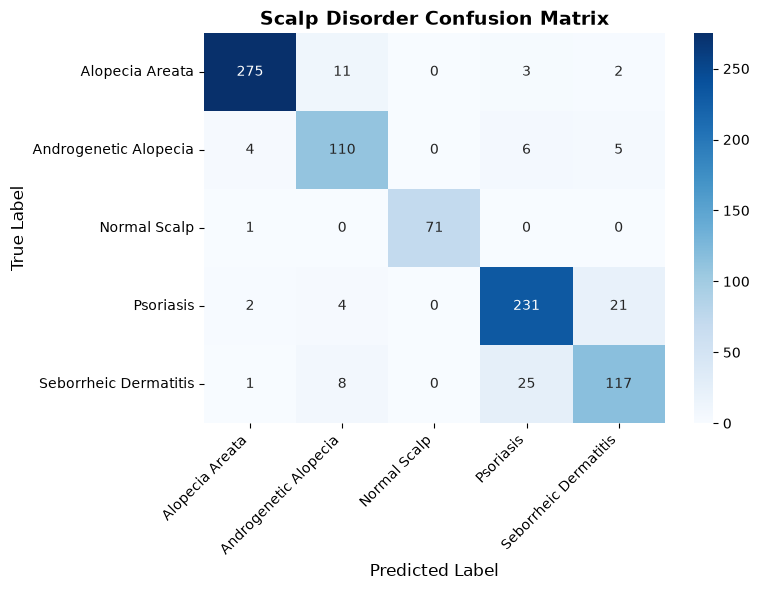

In [18]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Get your class names dynamically directly from the validation dataset folder names!
# This automatically grabs folder names like ['Normal', 'Dandruff', 'Psoriasis', etc.]
class_names = val_dataset.classes 

# 2. Print Overall Accuracy
accuracy = accuracy_score(all_labels, all_preds)
print(f"\n===============================")
print(f" Validation Accuracy: {accuracy * 100:.2f}%")
print(f"===============================\n")

# 3. Print Detailed Classification Report using the dynamic class names list
print("--- Detailed Classification Report ---")
print(classification_report(all_labels, all_preds, target_names=class_names))

# 4. Plot Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Scalp Disorder Confusion Matrix', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Running evaluation on validation dataset...

 Validation Accuracy: 89.63%

--- Detailed Classification Report ---


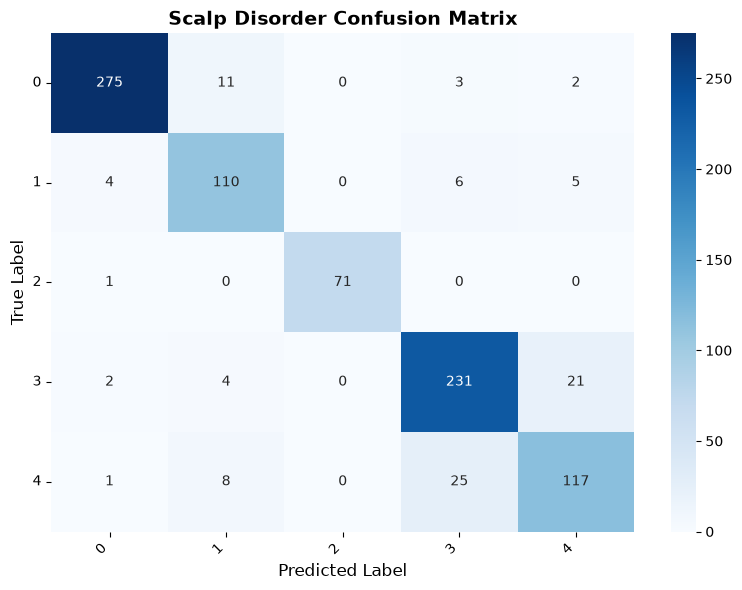

In [20]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Set model to evaluation mode
model.eval()
all_preds = []
all_labels = []

# Assuming you have a validation data loader named 'val_loader'
print("Running evaluation on validation dataset...")
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(DEVICE)
        labels = labels.to(DEVICE)
        
        outputs = model(inputs)
        _, preds = torch.max(outputs, dim=1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 2. Calculate Overall Accuracy
accuracy = accuracy_score(all_labels, all_preds)
print(f"\n==============================")
print(f" Validation Accuracy: {accuracy * 100:.2f}%")
print(f"==============================\n")

# 3. Print Detailed Classification Report (Precision, Recall, F1-Score per class)
print("--- Detailed Classification Report ---")
#print(classification_report(all_labels, all_preds, target_names=CLASSES))

# 4. Plot Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Scalp Disorder Confusion Matrix', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()